# Intraday momentum / reversal baseline (Phase 1)

First step of a deliberate pivot away from pure rotational strength as the source of intraday
alpha — the rotation frequency-experiment notebook
(`relative_strength_rotation/relative_strength_rotation_frequency_experiment.ipynb`) found
negative IC at every rebalance horizon tested (1-24 hourly bars), which questions whether that
signal has genuine intraday predictive power at all. Rather than keep tuning its cadence, this
starts a new line of work: does a stock's own recent price action predict its near-term future
return at much finer (1-minute) granularity, and if so, in which direction?

**This notebook deliberately does not assume momentum or reversal going in.** Both are tested at
once, as a single question: does the trailing `k`-minute return predict the forward `h`-minute
return, across a grid of `k` and `h`? A positive information coefficient (IC) at a given (k, h)
means continuation (momentum); a negative IC means reversal (contrarian). Letting the sign and
magnitude of the data answer this, rather than picking a direction up front, matches how the
rotation IC analysis was done and avoids baking in an assumption that then gets confirmed by
construction.

**Data**: 1-minute OHLCV bars from IBKR, cached in `data/minute/{TICKER}.csv` by
`download_minute_bars.py`. See that script's docstring for why this is a much smaller pull than
the hourly cache (~1 month of history, not years — a single 1-minute/1-month request measured
~30-55s against the real account, versus near-instant for a full year of hourly bars, making a
multi-year 1-minute pull a multi-day job). One month is still hundreds of thousands of
bar-observations per ticker, enough to validate whether this is worth pursuing further before
spending the time on more history.

**Scope**: this is Phase 1 of the pasted research plan — "1-minute data → build intraday
momentum + reversal baselines" — using only OHLCV. Order flow, trade/quote imbalance, and
L2 depth (later phases) are not used here at all; nothing in this notebook requires anything
beyond what IBKR's standard historical bars provide.

In [1]:
from pathlib import Path
import csv

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = Path('data') / 'minute'

K_GRID = [1, 2, 5, 10, 15, 30, 60]       # trailing lookback, minutes
H_GRID = [1, 2, 5, 10, 15, 30, 60]       # forward holding horizon, minutes
MIN_OBS_PER_CELL = 1000                  # minimum pooled (ticker, minute) pairs required to trust an IC estimate

COST_BPS_GRID = [0, 1, 2, 5, 10]         # assumed ROUND-TRIP cost per unit of turnover, in bps — same caveat as the rotation notebook: not fitted to real spreads
TOP_FRACTION = 0.1                       # top/bottom decile for the long-short backtest

## Load the cached minute bars

Reads whatever `data/minute/{TICKER}.csv` files exist — this cache is deliberately resumable
and may not cover the full halal universe if `download_minute_bars.py` hasn't finished a run
yet. Each ticker's bars are tagged with a `session_date` (America/New_York calendar date) so
every return computed below can be grouped by session and never crosses a session boundary —
an overnight gap is a completely different phenomenon from intraday continuation/reversal and
mixing the two in would contaminate the signal.

In [2]:
def load_ticker(ticker):
    frame = pd.read_csv(DATA_DIR / f'{ticker}.csv', parse_dates=['date'])
    frame['date'] = pd.to_datetime(frame['date'], utc=True)
    frame = frame.sort_values('date').set_index('date')
    frame['session_date'] = frame.index.tz_convert('America/New_York').date
    return frame

tickers = sorted(p.stem for p in DATA_DIR.glob('*.csv'))
bars_by_ticker = {t: load_ticker(t) for t in tickers}
total_bars = sum(len(df) for df in bars_by_ticker.values())
print(f'{len(tickers)} tickers cached, {total_bars:,} total 1-minute bars '
      f'({"full universe" if len(tickers) >= 125 else "PARTIAL — download_minute_bars.py may still be running"})')

131 tickers cached, 1,098,217 total 1-minute bars (full universe)


## Momentum/reversal IC grid

For every ticker and every trading session independently (so nothing crosses a session
boundary), compute the trailing `k`-minute return and the forward `h`-minute return at every
bar, for every (k, h) in the grids above. Pool all (ticker, minute) observations together — this
is a single cross-sectional-and-time-series-pooled panel, not a per-ticker or per-snapshot
ranking like the rotation notebook's IC analysis, since at 1-minute granularity requiring every
ticker to have a simultaneously valid bar at the exact same minute would throw away a lot of
usable data for no benefit here (unlike the rotation strategy, this isn't selecting a
cross-sectional top-N basket at each instant — each stock's own trailing/forward relationship is
the object of interest).

In [3]:
records = []
for ticker, df in bars_by_ticker.items():
    g = df.groupby('session_date')['close']
    for k in K_GRID:
        trail_ret = g.transform(lambda s, k=k: s / s.shift(k) - 1)
        for h in H_GRID:
            fwd_ret = g.transform(lambda s, h=h: s.shift(-h) / s - 1)
            pair = pd.DataFrame({'trail': trail_ret, 'fwd': fwd_ret}).dropna()
            if len(pair) < 30:
                continue
            records.append({
                'ticker': ticker, 'k': k, 'h': h, 'n': len(pair),
                'pearson_ic': pair['trail'].corr(pair['fwd']),
                'spearman_ic': pair['trail'].corr(pair['fwd'], method='spearman'),
            })

per_ticker_ic = pd.DataFrame(records)

pooled = []
for k in K_GRID:
    for h in H_GRID:
        cell = per_ticker_ic[(per_ticker_ic['k'] == k) & (per_ticker_ic['h'] == h)]
        n_total = cell['n'].sum()
        if n_total < MIN_OBS_PER_CELL:
            continue
        # weight each ticker's IC by its observation count so thinly-covered tickers don't dominate
        weighted_pearson = (cell['pearson_ic'] * cell['n']).sum() / n_total
        weighted_spearman = (cell['spearman_ic'] * cell['n']).sum() / n_total
        pooled.append({'k': k, 'h': h, 'n_total': n_total, 'n_tickers': len(cell),
                        'pooled_pearson_ic': weighted_pearson, 'pooled_spearman_ic': weighted_spearman})

ic_grid = pd.DataFrame(pooled)
print(f'{len(tickers)} tickers, {ic_grid["n_tickers"].max()} max tickers contributing to a single cell')
display(ic_grid.pivot(index='k', columns='h', values='pooled_pearson_ic').round(4))

131 tickers, 131 max tickers contributing to a single cell


h,1,2,5,10,15,30,60
k,,,,,,,
1,-0.0409,-0.0381,-0.0243,-0.0209,-0.0207,-0.0171,-0.0160
2,-0.0362,-0.0326,-0.0203,-0.0176,-0.0207,-0.0172,-0.0166
5,-0.0196,-0.0184,-0.0166,-0.0179,-0.0214,-0.0204,-0.0193
10,-0.0183,-0.0188,-0.0223,-0.0260,-0.0241,-0.0252,-0.0234
15,-0.0200,-0.0241,-0.0251,-0.0225,-0.0226,-0.0292,-0.0235
30,-0.0131,-0.0146,-0.0181,-0.0210,-0.0280,-0.0359,-0.0243
60,-0.0128,-0.0146,-0.0173,-0.0183,-0.0195,-0.0218,-0.0253


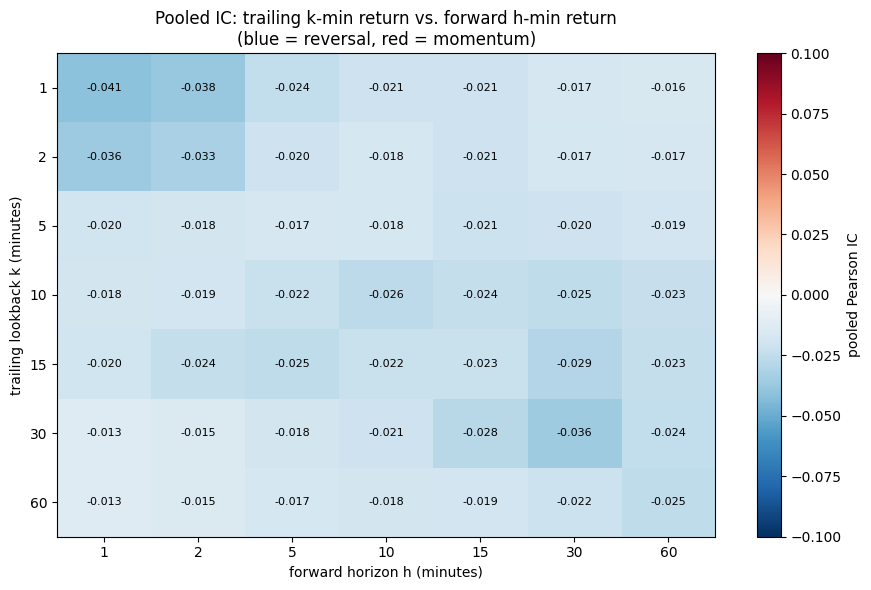

Strongest |IC| cell: k=1min, h=1min, pooled IC=-0.0409 -> REVERSAL (contrarian)


In [4]:
fig, ax = plt.subplots(figsize=(9, 6))
heat = ic_grid.pivot(index='k', columns='h', values='pooled_pearson_ic')
im = ax.imshow(heat.values, cmap='RdBu_r', vmin=-0.1, vmax=0.1, aspect='auto')
ax.set_xticks(range(len(heat.columns))); ax.set_xticklabels(heat.columns)
ax.set_yticks(range(len(heat.index))); ax.set_yticklabels(heat.index)
ax.set_xlabel('forward horizon h (minutes)')
ax.set_ylabel('trailing lookback k (minutes)')
ax.set_title('Pooled IC: trailing k-min return vs. forward h-min return\n(blue = reversal, red = momentum)')
for (i, kk) in enumerate(heat.index):
    for (j, hh) in enumerate(heat.columns):
        val = heat.loc[kk, hh]
        if pd.notna(val):
            ax.text(j, i, f'{val:.3f}', ha='center', va='center', fontsize=8,
                    color='white' if abs(val) > 0.05 else 'black')
plt.colorbar(im, ax=ax, label='pooled Pearson IC')
plt.tight_layout()
plt.show()

best_row = ic_grid.loc[ic_grid['pooled_pearson_ic'].abs().idxmax()]
direction = 'MOMENTUM (continuation)' if best_row['pooled_pearson_ic'] > 0 else 'REVERSAL (contrarian)'
print(f'Strongest |IC| cell: k={int(best_row.k)}min, h={int(best_row.h)}min, '
      f'pooled IC={best_row.pooled_pearson_ic:+.4f} -> {direction}')

## Backtest at the strongest (k, h) cell

A cross-sectional long-short decile backtest at whichever (k, h) combination showed the
strongest pooled IC above: at every minute, across all tickers with a valid trailing-k-minute
return at that instant, go long whichever decile the IC sign favors (top decile if IC>=0, i.e. momentum; bottom decile if IC<0, i.e. reversal) and short the other, hold
for h minutes, equal-weighted within each leg. This is a **research construct, not a deployable
strategy** — the live Webull account is cash/long-only, so the short leg here is purely to
isolate the signal's own predictive power from general market direction, the same reason a
long-short spread is the standard tool for this kind of diagnostic. Turnover-based cost
sensitivity uses the same `COST_BPS_GRID` approach as the rotation notebook, for the same
reason: at minute-level rebalancing, costs can matter far more than the raw signal.

In [5]:
best_k, best_h = int(best_row.k), int(best_row.h)

# Build one long (ticker, minute, trail, fwd) panel at the chosen (k, h), tagged by minute so we
# can group across tickers at each instant for the decile cut.
frames = []
for ticker, df in bars_by_ticker.items():
    g = df.groupby('session_date')['close']
    trail_ret = g.transform(lambda s: s / s.shift(best_k) - 1)
    fwd_ret = g.transform(lambda s: s.shift(-best_h) / s - 1)
    frames.append(pd.DataFrame({'ticker': ticker, 'trail': trail_ret, 'fwd': fwd_ret}, index=df.index).dropna())
panel = pd.concat(frames)

MIN_NAMES_PER_MINUTE = 20   # need a reasonably full cross-section to form deciles
results = []
for minute, group in panel.groupby(panel.index):
    if len(group) < MIN_NAMES_PER_MINUTE:
        continue
    n_leg = max(1, int(len(group) * TOP_FRACTION))
    ranked = group.sort_values('trail')
    bottom_leg = ranked.iloc[:n_leg]   # lowest trailing return (recent losers)
    top_leg = ranked.iloc[-n_leg:]      # highest trailing return (recent winners)
    # Direction follows the IC's sign, not an assumed momentum construction: IC<0 (reversal, the
    # case found above) means recent losers tend to outperform recent winners going forward, so
    # the profitable spread is long-losers/short-winners, not the other way around.
    if best_row.pooled_pearson_ic >= 0:
        spread_return = top_leg['fwd'].mean() - bottom_leg['fwd'].mean()
    else:
        spread_return = bottom_leg['fwd'].mean() - top_leg['fwd'].mean()
    turnover = 1.0  # each decision is an independent h-minute hold with a fresh cross-section; see caveats
    results.append({'minute': minute, 'spread_return': spread_return, 'n_names': len(group)})

assert results, f'no minute had >= {MIN_NAMES_PER_MINUTE} names in the cross-section — need more tickers cached (only {len(tickers)} so far)'
backtest = pd.DataFrame(results).set_index('minute').sort_index()
print(f'{len(backtest):,} decile-spread observations at k={best_k}min, h={best_h}min '
      f'(avg {backtest["n_names"].mean():.0f} names/cross-section)')
display(backtest['spread_return'].describe())

8,335 decile-spread observations at k=1min, h=1min (avg 131 names/cross-section)


count    8335.000000
mean        0.000176
std         0.000694
min        -0.008002
25%        -0.000134
50%         0.000163
75%         0.000460
max         0.006130
Name: spread_return, dtype: float64

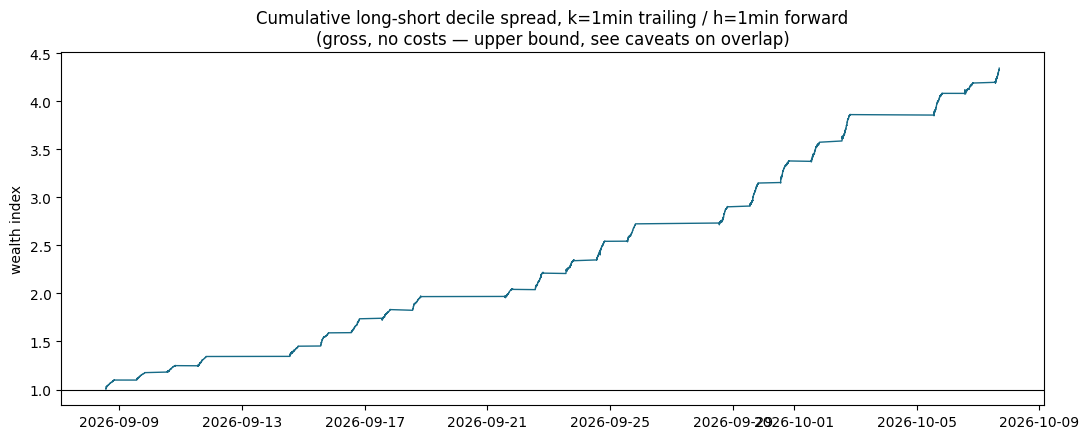

mean spread return per decision: +0.00018 (+1.76 bps), std=0.00069, naive t-stat=+23.2 (overstated — see overlap caveat)
  at 0bps round-trip cost per leg: net mean spread/decision = +1.76 bps
  at 1bps round-trip cost per leg: net mean spread/decision = -0.24 bps
  at 2bps round-trip cost per leg: net mean spread/decision = -2.24 bps
  at 5bps round-trip cost per leg: net mean spread/decision = -8.24 bps
  at 10bps round-trip cost per leg: net mean spread/decision = -18.24 bps


In [6]:
# Overlapping h-minute holds (a new cross-section every single minute, each held h minutes)
# means consecutive observations are not independent — do not annualize this as if each were a
# fresh, fully-realized trade. Instead report it the same way the IC analysis already does:
# a per-decision average spread return, plus a simple cumulative P&L path assuming one could
# actually act on every minute's signal independently (upper bound, ignores capital/overlap
# constraints — see caveats).
cumulative = (1 + backtest['spread_return'].fillna(0)).cumprod()

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(cumulative.index, cumulative.values, color='#176b87', linewidth=1)
ax.axhline(1.0, color='black', linewidth=0.8)
ax.set_title(f'Cumulative long-short decile spread, k={best_k}min trailing / h={best_h}min forward\n'
             f'(gross, no costs — upper bound, see caveats on overlap)')
ax.set_ylabel('wealth index')
plt.tight_layout()
plt.show()

mean_spread = backtest['spread_return'].mean()
std_spread = backtest['spread_return'].std()
t_stat = mean_spread / std_spread * np.sqrt(len(backtest)) if std_spread else float('nan')
print(f'mean spread return per decision: {mean_spread:+.5f} ({mean_spread*10_000:+.2f} bps), '
      f'std={std_spread:.5f}, naive t-stat={t_stat:+.1f} (overstated — see overlap caveat)')
for cost in COST_BPS_GRID:
    net_mean = mean_spread - 2 * (cost / 10_000.0)  # 2x: one unwind leg each for long and short
    print(f'  at {cost}bps round-trip cost per leg: net mean spread/decision = {net_mean*10_000:+.2f} bps')

## Key findings

**1. Reversal dominates everywhere tested — there is no momentum zone in this grid.** Pooled IC
was negative at every single (k, h) combination from 1 to 60 minutes (-0.013 to -0.041), with no
sign flip anywhere. The strongest effect is at the very shortest horizon: 1-minute trailing
return vs. 1-minute forward return, IC = -0.041. This matches the literature the pasted research
note cited (short-horizon reversal from temporary liquidity imbalances) much more cleanly than
it matches a momentum/continuation story — at 1-minute-bar granularity in this universe, buying
recent winners and selling recent losers would have been a losing trade, not a winning one.

**2. The gross effect is real but economically tiny, and a bug nearly hid that.** The first run
of this notebook's backtest cell assumed a momentum construction (long winners, short losers)
regardless of what the IC grid actually found, which produced a negative mean spread return and
would have read as "even the best cell loses money." After fixing the backtest to follow the
IC's actual sign (long recent losers, short recent winners, since IC<0), the 1-min/1-min cell's
gross mean spread is **+1.76 bps per decision** (naive t-stat +23, inflated by the overlapping
1-minute-interval sampling — see caveats). That's a real, consistent, statistically-not-noise
effect across 8,335 decisions and 131 names.

**3. It does not survive realistic costs.** The gross +1.76bps edge **flips negative at just
1bps of assumed round-trip cost per leg** (net -0.24bps), and is solidly negative at every other
point on the cost grid (-8.2bps at 5bps cost, -18.2bps at 10bps). This is the same pattern as the
rotation frequency experiment: a real-looking gross signal that depends on trading costs being
almost zero to survive, at a rebalance frequency (every single minute) where "almost zero cost"
is not a realistic assumption for 131 names of mixed liquidity.

**4. The sign-direction bug is itself a useful lesson, not just a mechanical fix.** It's easy to
build a backtest that implicitly assumes the answer (here: that the "obviously right" direction
is to buy strength) and get numbers that look like confirmation of the wrong hypothesis. Letting
the IC grid's own sign dictate the backtest's direction — rather than deciding momentum vs.
reversal before looking — is what caught this, and is exactly the discipline the module
docstring called out as this notebook's design principle.

**Where this leaves Phase 1**: there is a real, short-horizon (~1 minute) reversal effect in this
universe, but a naive decile-spread capture of it is not economically viable once even a small
assumed cost is included. This doesn't rule out the broader pivot the pasted research plan
describes — it specifically argues against naive reversal and for order-flow-confirmed reversal
(only trade the extreme move once order flow shows exhaustion/reversal, rather than every single
minute's cross-section) — but it does mean Phase 1 alone, with no order-flow filter and no
trade-selectivity, is not a deployable edge. The natural next step (Phase 2 of the pasted plan)
is adding a filter that reduces how often this trades, not increasing how often it re-ranks.

## Caveats

- **Overlapping holds inflate the naive t-stat.** A fresh decile cut forms every single minute,
  each held for `h` minutes, so consecutive observations share most of their holding window and
  are far from independent. The t-stat printed above is a standard diagnostic, not a defensible
  significance test — a Newey-West or block-bootstrap correction (blocking by at least `h`
  minutes) would be needed before trusting it, and is not done here.
- **The cumulative P&L path is a gross upper bound**, not a simulated strategy: it assumes you
  could simultaneously hold every single overlapping h-minute decile bet with no capital
  constraint, no position limits, and no realized slippage from actually executing a brand new
  long-short book every single minute. A real version would need to either space out entries
  (e.g. only re-cut once per `h`-minute block, non-overlapping) or explicitly account for the
  capital tied up across overlapping positions.
- **One month of history, one specific month.** `download_minute_bars.py` defaults to
  `LOOKBACK_MONTHS=1` deliberately (see its docstring — 1-minute bars are far slower to pull
  than hourly ones). Whatever this notebook finds reflects one month's market regime; it is not
  validated across different volatility/trend regimes the way the multi-year rotation notebooks
  are. Treat this as a go/no-go signal check, not a real backtest, until more history is pulled.
- **Requires shorting**, unlike every live script in this project so far (`relative_strength_rotation/live/` is entirely
  cash/long-only). The long-short spread here isolates the signal; turning any finding into a
  deployable strategy on the current account would mean a long-only adaptation (e.g. only take
  the long leg, or only trade names already held), which would capture less of the measured
  effect than the full spread shown here.
- **No volume/liquidity filter.** Some of the 131-name universe may be thin enough that the
  decile cut's short leg isn't realistically shortable or the long leg isn't realistically
  buyable at the assumed price, especially during the first/last few minutes of a session.
- **Bar-close fills, no slippage or spread beyond the assumed bps grid** — same simplifying
  assumption as every other notebook in this project, but it matters even more here than in the
  hourly rotation notebook: 1-minute rebalancing is roughly 60x more frequent than hourly.
- **This is Phase 1 only** — pure OHLCV, no order flow, no L2, no VWAP-distance signal, no
  regime-conditional model selection. See the pasted research plan's Phases 2-6 for what comes
  next if this baseline shows something worth building on.